# Part A: Numerical Prediction - Step 1: EDA & Preprocessing

This notebook handles Exploratory Data Analysis (EDA), missing value treatment, feature encoding, feature scaling, and train/test splitting for the numerical dataset (Car Price Regression).

In [29]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Load Dataset

In [6]:
# Load the dataset
data_path = "../data/CAR DETAILS FROM CAR DEKHO.csv"
df = pd.read_csv(data_path)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 2. Exploratory Data Analysis (EDA)
- Inspect shape, columns, and data types.
- Summary statistics for numerical and categorical features.
- Check for missing values and anomalies.
- Target variable distribution and correlation analysis.

In [16]:
# Basic structural inspection
print(df.info())
print(df.describe())

# MIssing values check
print("Missing values count:\n", df.isnull().sum())

# Duplicate rows check
print("Duplicate rows count:", df.duplicated().sum())

# Categorical columns summary
cat_cols = ["fuel", "seller_type", "transmission", "owner"]
for col in cat_cols:
    print("{} (unique: {})".format(col, df[col].nunique()))
    print(df[col].value_counts())
print("Unique car names:", df["name"].nunique())

# Correlation matrix for numerical columns
num_cols = ["year", "km_driven", "selling_price"]
corr = df[num_cols].corr()
print("Correlation matrix:\n", corr)

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB
None
              year  selling_price      km_driven
count  4340.000000   4.340000e+03    4340.000000
mean   2013.090783   5.041273e+05   66215.777419
std       4.215344   5.785487e+05   46644.102194
min    1992.000000   2.000000e+04       1.000000
25%    2011.000000   2.087498e+05   35000.000000
50%    2014.000000   3.500000e+05   60000.000000
75%    2016.000000   6.000000e+05   90000.000000
max    2020.000000   8.900000e+06  80659

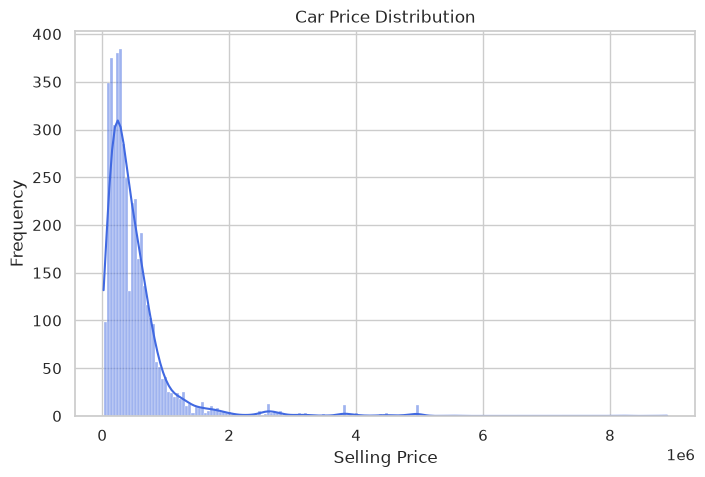

In [18]:
# Target variable distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['selling_price'], kde=True, color='royalblue')
plt.title('Car Price Distribution')
plt.xlabel('Selling Price')
plt.ylabel('Frequency')
plt.show()

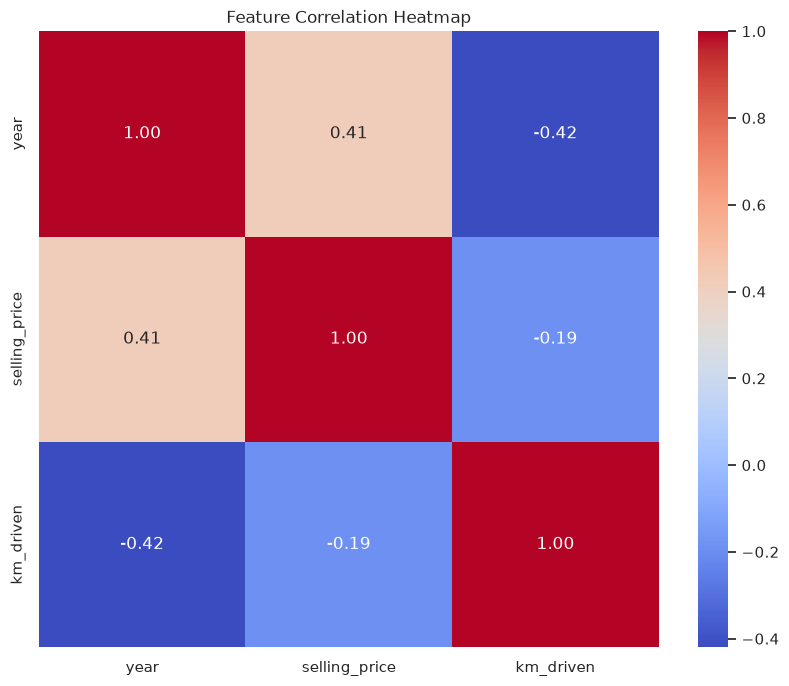

In [19]:
# Numerical correlations
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

## 3. Data Cleaning & Feature Preprocessing
- Handling missing values
- Encoding categorical variables (e.g. One-Hot Encoding)
- Scaling numerical features (StandardScaler)

In [43]:
# Remove duplicate rows & verify missing values
df_clean = df.drop_duplicates().copy()
print("Rows before deduplication:", len(df))
print("Rows after deduplication:", len(df_clean))

# Create engineered features on df_clean
df_clean["brand"] = df_clean["name"].apply(lambda x: str(x).split()[0])
df_clean["car_age"] = 2020 - df_clean["year"]
display(df_clean[["name", "brand", "year", "car_age", "selling_price"]].head())


# Define features and target
X = df_clean.drop(columns=['selling_price'])
y = df_clean['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

# Preprocessing: StandardScaler for numerical + OneHotEncoder for categorical
numerical_features = ["year", "car_age", "km_driven"]
categorical_features = ["fuel", "seller_type", "transmission", "owner", "brand"]

df_clean_preprocessed = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
).set_output(transform="pandas")

X_train_processed = df_clean_preprocessed.fit_transform(X_train)
X_test_processed = df_clean_preprocessed.transform(X_test)

print(f"Processed train shape: {X_train_processed.shape}, Processed test shape: {X_test_processed.shape}")

Rows before deduplication: 4340
Rows after deduplication: 3577


,name,brand,year,car_age,selling_price
0,Maruti 800 AC,Maruti,2007,13,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,13,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,8,600000
3,Datsun RediGO T Option,Datsun,2017,3,250000
4,Honda Amaze VX i-DTEC,Honda,2014,6,450000


Train set: (2861, 9), Test set: (716, 9)
Processed train shape: (2861, 44), Processed test shape: (716, 44)


## 4. Save Preprocessed Artifacts
Save processed train and test splits to allow modular continuation across subsequent notebooks.

In [44]:
os.makedirs("../data/processed", exist_ok=True)
joblib.dump((X_train, X_test, y_train, y_test), "../data/processed/numerical_split.joblib")
print("Preprocessing artifacts prepared successfully.")

Preprocessing artifacts prepared successfully.
